In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

In [2]:
df = pd.read_csv('payments.csv')
df.head()

,payment_id,order_id,payment_date,amount,payment_status,payment_method
0,PM00167,O00028,09/23/2024,67330.43,Success,Credit Card
1,PM00141,O00020,03-Nov-2024,"₹210,054.96",SUCCESS,UPI
2,PM00066,O00210,09/04/2025,75706.13,Success,Debit Card
3,PM00204,O00231,20/07/2024,27808.29,SUCCESS,Credit Card
4,PM00035,O00104,02/03/2024,131635.23,success,Debit Card


In [3]:
df.shape

(329, 6)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 329 entries, 0 to 328
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   payment_id      329 non-null    str  
 1   order_id        329 non-null    str  
 2   payment_date    319 non-null    str  
 3   amount          329 non-null    str  
 4   payment_status  329 non-null    str  
 5   payment_method  329 non-null    str  
dtypes: str(6)
memory usage: 15.6 KB


In [5]:
df.isnull().sum()

payment_id         0
order_id           0
payment_date      10
amount             0
payment_status     0
payment_method     0
dtype: int64

In [6]:
print(df.duplicated().sum())
print(df['payment_id'].duplicated().sum())
df[df['payment_id'].duplicated(keep=False)].sort_values('payment_id')

4
4


,payment_id,order_id,payment_date,amount,payment_status,payment_method
23,PM00067,O00005,06-Jan-2025,73078.38 INR,SUCCESS,Credit Card
153,PM00067,O00005,06-Jan-2025,73078.38 INR,SUCCESS,Credit Card
164,PM00137,O00261,10/05/2024,"$20,632.40",SUCCESS,NetBanking
244,PM00137,O00261,10/05/2024,"$20,632.40",SUCCESS,NetBanking
1,PM00141,O00020,03-Nov-2024,"₹210,054.96",SUCCESS,UPI
96,PM00141,O00020,03-Nov-2024,"₹210,054.96",SUCCESS,UPI
265,PM00237,O00015,25-Feb-2024,130237.17,success,UPI
319,PM00237,O00015,25-Feb-2024,130237.17,success,UPI


In [7]:
df[df['amount'].str.contains(r'[^\d.]')]['amount'].head(12)

1      ₹210,054.96
7      ₹102,114.63
11     ₹104,461.04
13     $181,349.01
18      ₹86,842.72
20     ₹136,898.84
22     ₹147,563.76
23    73078.38 INR
30      $56,711.33
34     ₹169,947.46
36      ₹85,908.79
37     $172,606.66
Name: amount, dtype: str

In [8]:
print(df['payment_status'].value_counts())
print()
print(df['payment_method'].value_counts())

payment_status
success     67
Succeded    58
SUCCESS     54
Success     52
pending     19
Refunded    17
FAILED      15
Pending     14
refunded    14
Failed      11
failed       8
Name: count, dtype: int64

payment_method
Debit Card     78
Credit Card    66
UPI            66
COD            63
NetBanking     56
Name: count, dtype: int64


In [9]:
print(df.groupby('order_id').size().value_counts())
multi = df[df['order_id'].duplicated(keep=False)].sort_values('order_id')
multi

1    311
2      9
Name: count, dtype: int64


,payment_id,order_id,payment_date,amount,payment_status,payment_method
23,PM00067,O00005,06-Jan-2025,73078.38 INR,SUCCESS,Credit Card
153,PM00067,O00005,06-Jan-2025,73078.38 INR,SUCCESS,Credit Card
319,PM00237,O00015,25-Feb-2024,130237.17,success,UPI
265,PM00237,O00015,25-Feb-2024,130237.17,success,UPI
1,PM00141,O00020,03-Nov-2024,"₹210,054.96",SUCCESS,UPI
96,PM00141,O00020,03-Nov-2024,"₹210,054.96",SUCCESS,UPI
207,PM00324,O00043,02/11/2024,111631.11,Pending,UPI
174,PM00114,O00043,20/06/2025,320939.45,SUCCESS,UPI
167,PM00307,O00067,17/09/2024,14920.73,success,Credit Card
237,PM00321,O00067,2024-12-22,5968.29,Pending,UPI


In [10]:
orders = pd.read_csv('orders_clean.csv', parse_dates=['order_date'])
print(sorted(set(df['order_id']) - set(orders['order_id'])))

['O90749', 'O93042', 'O93525', 'O94502', 'O94535', 'O97158', 'O97748', 'O98217']


In [11]:
def parse_date(x):
    if pd.isna(x):
        return pd.NaT
    x = str(x).strip()
    if x == '' or x.lower() == 'unknown':
        return pd.NaT
    if '/' in x:
        a, b, c = [int(i) for i in x.split('/')]
        if a > 12:
            return pd.Timestamp(year=c, month=b, day=a)
        if b > 12:
            return pd.Timestamp(year=c, month=a, day=b)
        return pd.Timestamp(year=c, month=b, day=a)
    if len(x) == 10 and x[4] == '-':
        return pd.to_datetime(x, format='%Y-%m-%d')
    return pd.to_datetime(x, format='%d-%b-%Y')


def is_ambiguous(x):
    if pd.isna(x) or '/' not in str(x):
        return False
    a, b, c = [int(i) for i in str(x).split('/')]
    return a <= 12 and b <= 12 and a != b

In [12]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(before, '->', len(df))
df['payment_id'].duplicated().sum()

329 -> 325


np.int64(0)

In [13]:
df['currency_symbol'] = df['amount'].str.extract(r'(₹|\$|INR)')[0].fillna('none')
df['amount'] = df['amount'].str.replace(r'[^\d.]', '', regex=True).astype(float)
df['currency_symbol'].value_counts()

currency_symbol
none    219
₹        64
$        28
INR      14
Name: count, dtype: int64

In [14]:
items = pd.read_csv('order_items.csv').drop_duplicates()
order_total = items.groupby('order_id')['line_total'].sum()
df['ratio'] = df['amount'] / df['order_id'].map(order_total)
df.groupby('currency_symbol')['ratio'].describe()

,count,mean,std,min,25%,50%,75%,max
currency_symbol,,,,,,,,
$,28.0,0.991914,0.224417,0.5,1.0,1.0,1.0,1.523579
INR,14.0,1.021429,0.129666,0.7,1.0,1.0,1.0,1.300000
none,214.0,0.962856,0.187931,0.4,1.0,1.0,1.0,1.300000
₹,60.0,0.987177,0.165034,0.4,1.0,1.0,1.0,1.309474


In [15]:
df = df.drop(columns=['currency_symbol', 'ratio'])
df['amount'].describe()

count       325.000000
mean      90230.796031
std       62740.404550
min        3184.810000
25%       42612.850000
50%       80420.700000
75%      124164.450000
max      333060.900000
Name: amount, dtype: float64

In [16]:
status_map = {'success': 'Success', 'succeded': 'Success', 'pending': 'Pending',
              'failed': 'Failed', 'refunded': 'Refunded'}
df['payment_status'] = df['payment_status'].str.strip().str.lower().map(status_map)
print(df['payment_status'].isnull().sum())
df['payment_status'].value_counts()

0


payment_status
Success     227
Failed       34
Pending      33
Refunded     31
Name: count, dtype: int64

In [17]:
df['payment_method'] = df['payment_method'].str.strip()
df['payment_method'].value_counts()

payment_method
Debit Card     78
Credit Card    65
UPI            64
COD            63
NetBanking     55
Name: count, dtype: int64

In [18]:
df['payment_ambiguous'] = df['payment_date'].apply(is_ambiguous)
df['payment_date'] = df['payment_date'].apply(parse_date)
print(df['payment_ambiguous'].sum(), df['payment_date'].isnull().sum())
df['payment_date'].describe()

56 10


count                    315
mean     2024-11-06 02:40:00
min      2024-01-01 00:00:00
25%      2024-05-10 12:00:00
50%      2024-11-02 00:00:00
75%      2025-04-28 12:00:00
max      2025-11-07 00:00:00
Name: payment_date, dtype: object

In [19]:
df['order_orphan'] = ~df['order_id'].isin(orders['order_id'])
print(df['order_orphan'].sum())
df[df['order_orphan']]

8


,payment_id,order_id,payment_date,amount,payment_status,payment_method,payment_ambiguous,order_orphan
11,PM00125,O93042,2024-07-22,104461.04,Success,COD,False,True
55,PM00264,O97158,2024-07-23,27430.41,Success,Credit Card,False,True
79,PM00316,O93525,2024-12-09,70145.67,Success,NetBanking,True,True
87,PM00277,O94502,2024-02-06,107841.66,Failed,COD,False,True
171,PM00192,O98217,2024-03-02,124164.45,Refunded,UPI,False,True
233,PM00026,O94535,2025-06-12,45226.39,Refunded,COD,False,True
266,PM00294,O90749,2024-04-04,224837.10,Success,UPI,False,True
298,PM00156,O97748,2025-05-27,107279.68,Success,UPI,False,True


In [20]:
df = df.merge(orders[['order_id', 'order_date']], on='order_id', how='left')
df['date_before_order'] = df['payment_date'] < df['order_date']
print(df['date_before_order'].sum(), len(df))

165 325


In [21]:
df = df.drop(columns='order_date')
success_count = df[df['payment_status'] == 'Success'].groupby('order_id').size()
multi_success = success_count[success_count > 1].index
df['multi_success'] = df['order_id'].isin(multi_success)
print(df['multi_success'].sum())
df[df['multi_success']].sort_values('order_id')

0


,payment_id,order_id,payment_date,amount,payment_status,payment_method,payment_ambiguous,order_orphan,date_before_order,multi_success


In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 325 entries, 0 to 324
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   payment_id         325 non-null    str           
 1   order_id           325 non-null    str           
 2   payment_date       315 non-null    datetime64[us]
 3   amount             325 non-null    float64       
 4   payment_status     325 non-null    str           
 5   payment_method     325 non-null    str           
 6   payment_ambiguous  325 non-null    bool          
 7   order_orphan       325 non-null    bool          
 8   date_before_order  325 non-null    bool          
 9   multi_success      325 non-null    bool          
dtypes: bool(4), datetime64[us](1), float64(1), str(4)
memory usage: 16.6 KB


In [23]:
df.isnull().sum()

payment_id            0
order_id              0
payment_date         10
amount                0
payment_status        0
payment_method        0
payment_ambiguous     0
order_orphan          0
date_before_order     0
multi_success         0
dtype: int64

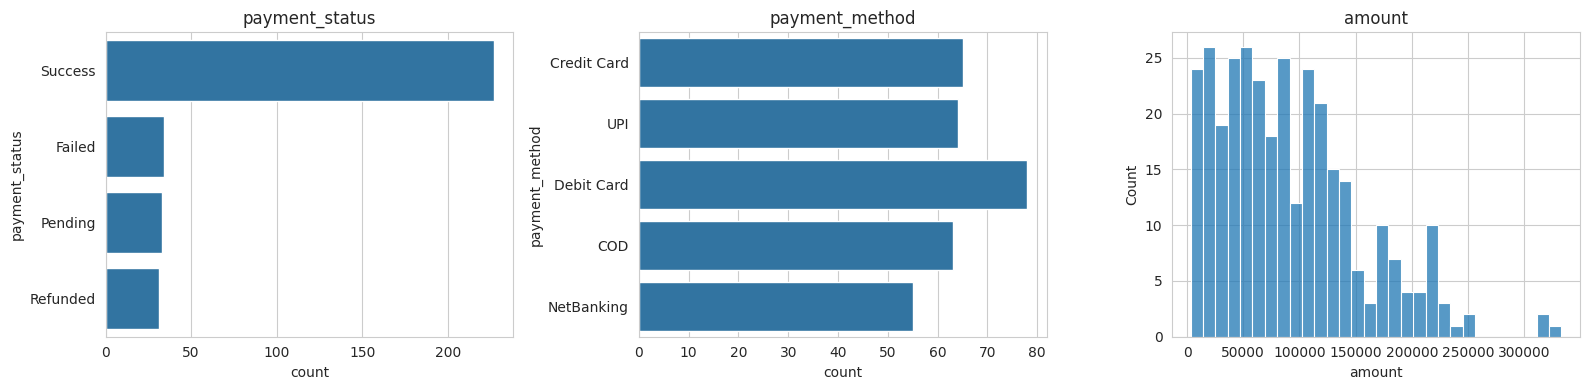

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, y='payment_status', order=df['payment_status'].value_counts().index, ax=ax[0])
sns.countplot(data=df, y='payment_method', ax=ax[1])
sns.histplot(df['amount'], bins=30, ax=ax[2])
ax[0].set_title('payment_status')
ax[1].set_title('payment_method')
ax[2].set_title('amount')
plt.tight_layout()
plt.show()

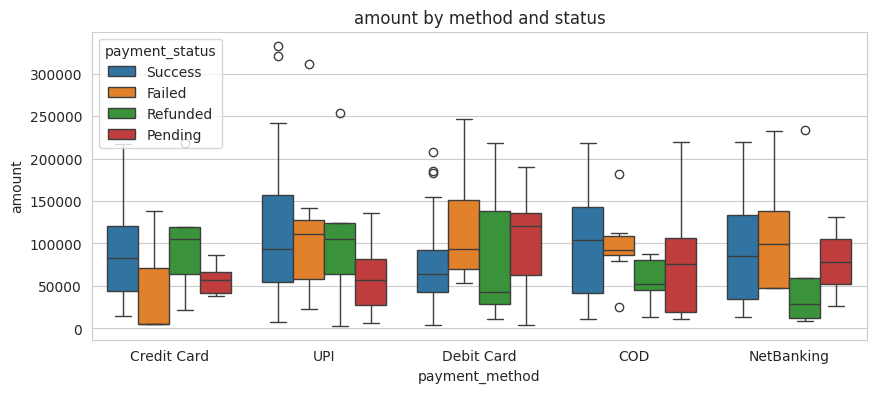

In [25]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x='payment_method', y='amount', hue='payment_status')
plt.title('amount by method and status')
plt.show()

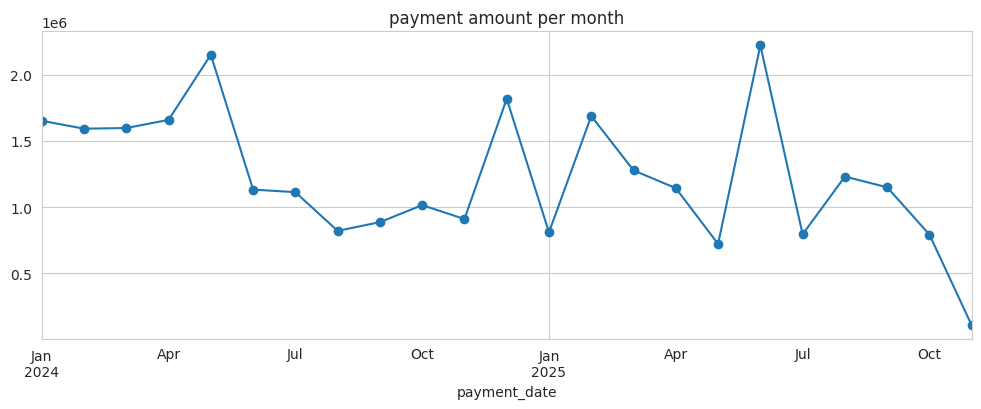

In [26]:
monthly = df.groupby(df['payment_date'].dt.to_period('M'))['amount'].sum()
plt.figure(figsize=(12, 4))
monthly.plot(marker='o')
plt.title('payment amount per month')
plt.show()

In [27]:
df.to_csv('payments_clean.csv', index=False)
df.head()

,payment_id,order_id,payment_date,amount,payment_status,payment_method,payment_ambiguous,order_orphan,date_before_order,multi_success
0,PM00167,O00028,2024-09-23,67330.43,Success,Credit Card,False,False,True,False
1,PM00141,O00020,2024-11-03,210054.96,Success,UPI,False,False,False,False
2,PM00066,O00210,2025-04-09,75706.13,Success,Debit Card,True,False,False,False
3,PM00204,O00231,2024-07-20,27808.29,Success,Credit Card,False,False,False,False
4,PM00035,O00104,2024-03-02,131635.23,Success,Debit Card,True,False,False,False
